In [2]:
import os
import torch
import anthropic

In [3]:
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.feature_extraction.text import TfidfVectorizer

In [4]:
from sentence_transformers import SentenceTransformer

c:\Users\User\MLX_wd\production-ml\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline


In [6]:
import tqdm

In [7]:
complaints = pd.read_csv("data/complaints.csv")
complaints.shape

(160932, 20)

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

In [9]:
from lightgbm import LGBMClassifier, early_stopping
from sklearn.preprocessing import LabelEncoder

In [10]:
import torch
from torch import nn

## Given a complaint, predict which team should handle it

In [11]:
complaints.head()

,Date received,Product,Sub-product,Issue,Sub-issue,Consumer complaint narrative,Company public response,Company,State,ZIP code,Tags,Consumer consent provided?,Submitted via,Date sent to company,Company response to consumer,Timely response?,Consumer disputed?,Complaint ID,routing_team,ZIP3
0,2023-01-01,"Credit reporting, credit repair services, or o...",Credit reporting,Problem with a credit reporting company's inve...,Their investigation did not fix an error on yo...,XXXX is unlawfully placing redundant data in t...,NaN,"EQUIFAX, INC.",NC,28411,NaN,Consent provided,Web,2023-01-01,Closed with explanation,Yes,NaN,6382152,credit_reporting,284
1,2023-01-01,Credit card or prepaid card,Payroll card,Trouble using the card,Trouble using the card to spend money in a sto...,On XXXX XXXX I received an email stating a tem...,NaN,Payfare International Inc.,CA,95003,NaN,Consent provided,Web,2023-01-01,Closed with explanation,Yes,NaN,6382160,prepaid_card,950
2,2023-01-01,Credit card or prepaid card,General-purpose credit card or charge card,Problem with a purchase shown on your statement,Card was charged for something you did not pur...,There were two charges on my account I did not...,NaN,DISCOVER BANK,UNITED STATES MINOR OUTLYING ISLANDS,95823,NaN,Consent provided,Web,2023-01-01,Closed with explanation,Yes,NaN,6382163,credit_card,958
3,2023-01-01,"Credit reporting, credit repair services, or o...",Credit reporting,Incorrect information on your report,Account status incorrect,Hello. Theres has been an illegal action place...,Company has responded to the consumer and the ...,"Prosper Marketplace, Inc.",ID,832XX,Servicemember,Consent provided,Web,2023-01-01,Closed with non-monetary relief,Yes,NaN,6382180,credit_reporting,832
4,2023-01-01,Debt collection,Credit card debt,False statements or representation,Attempted to collect wrong amount,On XX/XX/2022 received notification from XXXX ...,Company has responded to the consumer and the ...,SYNCHRONY FINANCIAL,MO,655XX,Servicemember,Consent provided,Web,2023-01-01,Closed with explanation,Yes,NaN,6382186,debt_collection,655


In [12]:
# Exploratory Data Analysis

print(f"Shape: {complaints.shape}")
complaints.head()
complaints.columns.tolist()
complaints.info()
complaints.isna().sum().sort_values(ascending=False)
complaints.describe(include="all").T

for col in ["Product", "Issue", "State", "Company", "Submitted via"]:
    if col in complaints.columns:
        print(f"\nTop 10 values for {col}:")
        print(complaints[col].value_counts(dropna=False).head(10))


Shape: (160932, 20)
<class 'pandas.DataFrame'>
RangeIndex: 160932 entries, 0 to 160931
Data columns (total 20 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   Date received                 160932 non-null  str    
 1   Product                       160932 non-null  str    
 2   Sub-product                   160932 non-null  str    
 3   Issue                         160932 non-null  str    
 4   Sub-issue                     153663 non-null  str    
 5   Consumer complaint narrative  160932 non-null  str    
 6   Company public response       95773 non-null   str    
 7   Company                       160932 non-null  str    
 8   State                         160542 non-null  str    
 9   ZIP code                      160932 non-null  str    
 10  Tags                          15984 non-null   str    
 11  Consumer consent provided?    160932 non-null  str    
 12  Submitted via                 16093

In [13]:
# Routing-model EDA: exclude Product and Sub-product, keep every other field as input

exclude_cols = ["Product", "Sub-product", "routing_team", "Complaint ID", "Submitted via", "Consumer disputed?"]
feature_cols = [c for c in complaints.columns if c not in exclude_cols]
target_col = "routing_team"

print(f"Total rows: {complaints.shape[0]}")
print(f"Feature count: {len(feature_cols)}")
print(f"Target column: {target_col}")
print(f"Feature columns: {feature_cols}")

print("\nTarget distribution:")
print(complaints[target_col].value_counts().head(10))

print("\nMissing values in model features:")
print(complaints[feature_cols].isna().sum().sort_values(ascending=False).head(15).to_string())

print("\nUnique values per feature:")
print(complaints[feature_cols].nunique().sort_values(ascending=False).head(15).to_string())

# Keep the dataset ready for modeling
X = complaints[feature_cols]
y = complaints[target_col]
print(f"\nX shape: {X.shape}")
print(f"y shape: {y.shape}")


Total rows: 160932
Feature count: 14
Target column: routing_team
Feature columns: ['Date received', 'Issue', 'Sub-issue', 'Consumer complaint narrative', 'Company public response', 'Company', 'State', 'ZIP code', 'Tags', 'Consumer consent provided?', 'Date sent to company', 'Company response to consumer', 'Timely response?', 'ZIP3']

Target distribution:
routing_team
credit_reporting    113929
debt_collection      11950
credit_card          11113
checking_savings      9401
mortgage              4588
money_transfer        2775
vehicle_loan          2440
student_loan          2321
personal_loan         1418
prepaid_card           997
Name: count, dtype: int64

Missing values in model features:
Tags                            144948
Company public response          65159
Sub-issue                         7269
State                              390
Issue                                0
Date received                        0
Company                              0
Consumer complaint narrati

In [14]:
# Temporal drift check: does the complaint mix or missingness change over time?

df_time = complaints.copy()
for c in ["Date received", "Date sent to company"]:
    if c in df_time.columns:
        df_time[c] = pd.to_datetime(df_time[c], errors="coerce")

df_time["month"] = df_time["Date received"].dt.to_period("M")
df_time["year"] = df_time["Date received"].dt.year

print("Rows by year:")
print(df_time["year"].value_counts().sort_index().to_string())

print("\nRows by month (first 12):")
print(df_time["month"].value_counts().sort_index().head(12).to_string())

print("\nRouting-team mix by month:")
print(df_time.groupby("month")["routing_team"].value_counts(normalize=True).unstack(fill_value=0).head(12).to_string())

print("\nMissingness by month for key fields:")
missing_cols = ["State", "Sub-issue", "Tags", "Company public response", "Consumer disputed?"]
miss = df_time.groupby("month")[missing_cols].apply(lambda g: g.isna().mean())
print(miss.head(12).to_string())

print("\nTop issue share by year:")
print(df_time.groupby("year")["Issue"].value_counts(normalize=True).unstack(fill_value=0).head().to_string())


Rows by year:
year
2023    153278
2024      7654

Rows by month (first 12):
month
2023-01    10016
2023-02     8657
2023-03    10346
2023-04     9006
2023-05    10216
2023-06    10391
2023-07    10255
2023-08    11614
2023-09    10743
2023-10    17284
2023-11    15207
2023-12    29543
Freq: M

Routing-team mix by month:
routing_team  checking_savings  credit_card  credit_reporting  debt_collection  money_transfer  mortgage  personal_loan  prepaid_card  student_loan  vehicle_loan
month                                                                                                                                                            
2023-01               0.089856     0.057508          0.664038         0.078075        0.021166  0.040236       0.009784      0.006689      0.010383      0.022264
2023-02               0.065034     0.057757          0.705556         0.079358        0.021486  0.033152       0.011436      0.003234      0.007046      0.015941
2023-03               0.056157

In [15]:
missing = complaints.isna().mean().sort_values(ascending=False)
print(missing.head(20))

print("duplicate rows:", complaints.duplicated().sum())
print("duplicate:", complaints["Consumer complaint narrative"].duplicated().sum(),)

Consumer disputed?              1.000000
Tags                            0.900679
Company public response         0.404885
Sub-issue                       0.045168
State                           0.002423
Sub-product                     0.000000
Product                         0.000000
Date received                   0.000000
Issue                           0.000000
Company                         0.000000
ZIP code                        0.000000
Consumer complaint narrative    0.000000
Consumer consent provided?      0.000000
Submitted via                   0.000000
Company response to consumer    0.000000
Date sent to company            0.000000
Timely response?                0.000000
Complaint ID                    0.000000
routing_team                    0.000000
ZIP3                            0.000000
dtype: float64
duplicate rows: 0
duplicate: 34852


In [16]:
print("Product labels:")
print(sorted(complaints["Product"].dropna().unique()))

print("Number of Issue labels:")
print(complaints["Issue"].nunique(dropna=True))

Product labels:
['Checking or savings account', 'Credit card', 'Credit card or prepaid card', 'Credit reporting or other personal consumer reports', 'Credit reporting, credit repair services, or other personal consumer reports', 'Debt collection', 'Debt or credit management', 'Money transfer, virtual currency, or money service', 'Mortgage', 'Payday loan, title loan, or personal loan', 'Payday loan, title loan, personal loan, or advance loan', 'Prepaid card', 'Student loan', 'Vehicle loan or lease']
Number of Issue labels:
89


In [17]:
# Compare date fields to check whether they are identical or differ by a lag

df_dates = complaints[["Date received", "Date sent to company"]].copy()
df_dates["Date received"] = pd.to_datetime(df_dates["Date received"], errors="coerce")
df_dates["Date sent to company"] = pd.to_datetime(df_dates["Date sent to company"], errors="coerce")

identical = df_dates["Date received"].eq(df_dates["Date sent to company"])
print(f"Identical rows: {identical.sum()}")
print(f"Different rows: {(~identical).sum()}")
print("\nSample of differing rows:")
print(df_dates.loc[~identical, ["Date received", "Date sent to company"]].head(10).to_string(index=False))

lag_days = (df_dates["Date sent to company"] - df_dates["Date received"]).dt.days
print("\nLag in days summary:")
print(lag_days.describe())


Identical rows: 154503
Different rows: 6429

Sample of differing rows:
Date received Date sent to company
   2023-01-01           2023-01-20
   2023-01-01           2023-03-14
   2023-01-01           2023-01-10
   2023-01-01           2023-01-20
   2023-01-01           2023-01-23
   2023-01-01           2023-01-20
   2023-01-01           2023-01-03
   2023-01-01           2023-01-19
   2023-01-02           2023-01-04
   2023-01-02           2023-01-23

Lag in days summary:
count    160932.000000
mean          0.594997
std           4.261198
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max         196.000000
dtype: float64


In [18]:
def prepare_complaints(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    df["Date received"] = pd.to_datetime(
        df["Date received"],
        errors="coerce",
    )

    df["Consumer complaint narrative"] = (
        df["Consumer complaint narrative"]
        .fillna("")
        .str.strip()
    )

    return df


complaints = prepare_complaints(complaints)

In [19]:
train = complaints[
    complaints["Date received"] < "2023-10-01"
].copy()

validation = complaints[
    (complaints["Date received"] >= "2023-10-01")
    & (complaints["Date received"] < "2023-12-01")
].copy()

test = complaints[
    complaints["Date received"] >= "2023-12-01"
].copy()

print("train:", len(train))
print("validation:", len(validation))
print("test:", len(test))

train: 91244
validation: 32491
test: 37197


In [20]:
print(train["routing_team"].value_counts())
print(train["routing_team"].value_counts(normalize=True))


routing_team
credit_reporting    65947
debt_collection      6641
credit_card          5853
checking_savings     5288
mortgage             2444
money_transfer       1538
vehicle_loan         1382
personal_loan         827
student_loan          811
prepaid_card          513
Name: count, dtype: int64
routing_team
credit_reporting    0.722754
debt_collection     0.072783
credit_card         0.064147
checking_savings    0.057954
mortgage            0.026785
money_transfer      0.016856
vehicle_loan        0.015146
personal_loan       0.009064
student_loan        0.008888
prepaid_card        0.005622
Name: proportion, dtype: float64


In [21]:
majority_class = train["routing_team"].value_counts().idxmax()

baseline_predictions =  np.repeat(majority_class, len(validation),)


In [22]:
print(
    "validation accuracy:",
    accuracy_score(
        validation["routing_team"],
        baseline_predictions,
    ),
)

print(
    "validation macro F1:",
    f1_score(
        validation["routing_team"],
        baseline_predictions,
        average="macro",
    ),
)

validation accuracy: 0.7049336739404758
validation macro F1: 0.0826933838794115


In [23]:
vectorizer = TfidfVectorizer(
    ngram_range = (1,2),
    min_df=3,
    max_features=300_000,
    sublinear_tf=True,
    )

X_train = vectorizer.fit_transform(train["Consumer complaint narrative"])
X_validation = vectorizer.transform(validation["Consumer complaint narrative"])

In [24]:
model = Pipeline([
    ("tfidf",
     TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=3,
        max_features=300_000,
        sublinear_tf=True,
        ),
    ),
    ("classifier",
     LogisticRegression(
         C=4,
         max_iter=2000,
     ),
    ),
])

In [25]:
model.fit(train["Consumer complaint narrative"], train["routing_team"])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](10,)","['checking_savings','credit_card','credit_reporting',...,'prepaid_card', 'student_loan','vehicle_loan']"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",3
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",300000
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'


In [26]:
validation_predictions = model.predict(validation["Consumer complaint narrative"])

In [27]:
validation_accuracy = accuracy_score(
    validation["routing_team"],
    validation_predictions,
)

validation_macro_f1 = f1_score(
    validation["routing_team"],
    validation_predictions,
    average="macro",
)

print("validation accuracy:", validation_accuracy)
print("validation macro F1:", validation_macro_f1)

validation accuracy: 0.8914468622079961
validation macro F1: 0.7217094908741383


In [28]:
print(
    classification_report(
        validation["routing_team"],
        validation_predictions
    )
)

                  precision    recall  f1-score   support

checking_savings       0.74      0.87      0.80      1697
     credit_card       0.80      0.76      0.78      2430
credit_reporting       0.93      0.97      0.95     22904
 debt_collection       0.73      0.57      0.64      2183
  money_transfer       0.78      0.54      0.64       591
        mortgage       0.86      0.84      0.85       817
   personal_loan       0.68      0.33      0.44       292
    prepaid_card       0.93      0.45      0.61       199
    student_loan       0.96      0.79      0.86       901
    vehicle_loan       0.75      0.56      0.64       477

        accuracy                           0.89     32491
       macro avg       0.82      0.67      0.72     32491
    weighted avg       0.89      0.89      0.89     32491



In [29]:
report_dict = classification_report(
        validation["routing_team"],
        validation_predictions,
        output_dict=True
    )
print(report_dict)

{'checking_savings': {'precision': 0.7410938283993979, 'recall': 0.8703594578668238, 'f1-score': 0.8005420054200542, 'support': 1697.0}, 'credit_card': {'precision': 0.8006962576153177, 'recall': 0.757201646090535, 'f1-score': 0.7783417935702199, 'support': 2430.0}, 'credit_reporting': {'precision': 0.9281182167306729, 'recall': 0.970747467691233, 'f1-score': 0.9489543320529236, 'support': 22904.0}, 'debt_collection': {'precision': 0.7280187573270809, 'recall': 0.5689418231791114, 'f1-score': 0.6387246078683466, 'support': 2183.0}, 'money_transfer': {'precision': 0.78239608801956, 'recall': 0.5414551607445008, 'f1-score': 0.64, 'support': 591.0}, 'mortgage': {'precision': 0.8634085213032582, 'recall': 0.8433292533659731, 'f1-score': 0.853250773993808, 'support': 817.0}, 'personal_loan': {'precision': 0.6834532374100719, 'recall': 0.3253424657534247, 'f1-score': 0.4408352668213457, 'support': 292.0}, 'prepaid_card': {'precision': 0.9278350515463918, 'recall': 0.45226130653266333, 'f1-sc

In [30]:
errors = validation.copy()
errors["prediction"] = validation_predictions
errors = errors[errors["prediction"] != errors["routing_team"]]
errors[[
        "Consumer complaint narrative",
        "routing_team",
        "prediction",
        "Company",
]].head(20)

,Consumer complaint narrative,routing_team,prediction,Company
91245,"On XX/XX/2023, I sent Truist Financial Corp a ...",credit_reporting,debt_collection,TRUIST FINANCIAL CORPORATION
91246,NOTICE TO PRINCIPAL IS NOTICE TO AGENT NOTICE ...,debt_collection,credit_reporting,Resurgent Capital Services L.P.
91247,I contacted this company in XXXX & XXXX regard...,debt_collection,credit_reporting,FIRST PORTFOLIO SERVICING INC
91251,I bought a perfume from XXXX and returned it i...,personal_loan,credit_card,"Block, Inc."
91258,XXXX Ten fraudulent charges appear on my Chas...,money_transfer,checking_savings,JPMORGAN CHASE & CO.
91268,Paid settlement for {$270.00} on XXXX in excha...,debt_collection,credit_reporting,ENCORE CAPITAL GROUP INC.
91282,Paid off loan and loan company continued to gi...,vehicle_loan,personal_loan,"American Credit Acceptance, LLC"
91288,XXXXXXXX XXXX XXXX XXXXXXXX Dear Collections a...,checking_savings,credit_reporting,"Fidelity National Information Services, Inc. (..."
91318,On XX/XX/2023 I viewed my XXXX consumer report...,debt_collection,credit_reporting,Velocity Portfolio Group
91328,I am writing to formally complain about the in...,vehicle_loan,credit_reporting,FORD MOTOR CREDIT CO.


In [31]:
test_predictions = model.predict(
    test["Consumer complaint narrative"]
)

print(
    "accuracy:",
    accuracy_score(test["routing_team"], test_predictions),
)

print(
    "macro F1:",
    f1_score(
        test["routing_team"],
        test_predictions,
        average="macro",
    ),
)

accuracy: 0.8694787214022637
macro F1: 0.7157391005992645


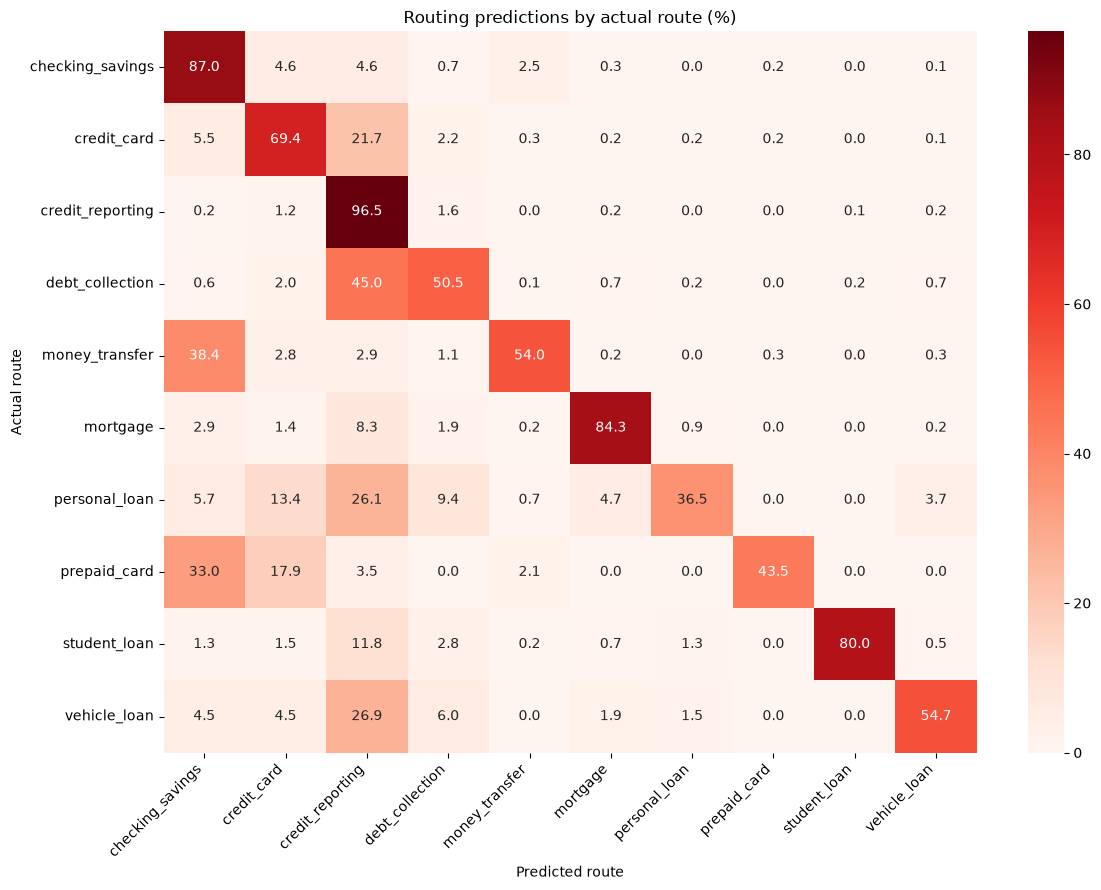

In [32]:
y_test = test["routing_team"]
y_pred = test_predictions

matrix = pd.crosstab(
    pd.Series(y_test, name="Actual route"),
    pd.Series(y_pred, index=y_test.index, name="Predicted route"),
    normalize="index",
) * 100

plt.figure(figsize=(12, 9))
sns.heatmap(matrix, annot=True, fmt=".1f", cmap="Reds")
plt.xlabel("Predicted route")
plt.ylabel("Actual route")
plt.title("Routing predictions by actual route (%)")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()


## LightGBM

In [33]:
for split in (train, validation, test):
    split["ZIP3"] = split["ZIP code"].astype("string").str[:3]

features = ["Company", "State", "ZIP3", "Tags"]

In [34]:
X_train = train[features].copy()
X_validation = validation[features].copy()


for column in features:
    train_values = X_train[column].fillna("MISSING").astype(str)
    validation_values = X_validation[column].fillna("MISSING").astype(str)
    counts = train_values.value_counts()
    keep = counts[counts >= 20].index
    categories = [*keep, "OTHER"]

    X_train[column] = pd.Categorical(
        train_values.where(train_values.isin(keep), "OTHER"),
        categories=categories,
    )
    X_validation[column] = pd.Categorical(
        validation_values.where(validation_values.isin(keep), "OTHER"),
        categories=categories,
    )

label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(train["routing_team"])
y_validation = label_encoder.transform(validation["routing_team"])

model_gbt = LGBMClassifier(
    objective="multiclass",
    n_estimators=500,
    random_state=42,
    verbose=-1,
)

model_gbt.fit(
    X_train,
    y_train,
    eval_set=[(X_validation, y_validation)],
    callbacks=[early_stopping(20, verbose=False)],
)

gbt_predictions = model_gbt.predict(X_validation)


print("validation accuracy:", accuracy_score(y_validation, gbt_predictions))
print("validation macro F1:", f1_score(y_validation, gbt_predictions, average="macro"))
print("boosting rounds:", model_gbt.best_iteration_)

c:\Users\User\MLX_wd\production-ml\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


validation accuracy: 0.8196731402542242
validation macro F1: 0.558558720481427
boosting rounds: 21


## LLM Classification Model

In [35]:
complaints["Date received"] = pd.to_datetime(
    complaints["Date received"],
    errors="coerce",
)

complaints["Consumer complaint narrative"] = (
    complaints["Consumer complaint narrative"]
    .fillna("")
    .str.strip()
)

train = complaints[
    complaints["Date received"] < "2023-10-01"
].copy()

validation = complaints[
    (complaints["Date received"] >= "2023-10-01")
    & (complaints["Date received"] < "2023-12-01")
].copy()

test = complaints[
    complaints["Date received"] >= "2023-12-01"
].copy()

print(len(train), len(validation), len(test))

91244 32491 37197


In [40]:
def scores(y_true, predictions, weights=None):
    accuracy = accuracy_score(
        y_true,
        predictions,
        sample_weight=weights,
    )
    macro_f1 = f1_score(
        y_true,
        predictions,
        average="macro",
        sample_weight=weights,
    )
    return round(accuracy, 3), round(macro_f1, 3)


benchmark_validation = benchmark.predict(
    validation["Consumer complaint narrative"]
)

print(scores(validation["routing_team"], benchmark_validation))

(0.891, 0.722)


In [39]:
benchmark = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=3,
            max_features=300_000,
            sublinear_tf=True,
        ),
    ),
    (
        "classifier",
        LogisticRegression(
            C=4,
            max_iter=2000,
        ),
    ),
])

benchmark.fit(
    train["Consumer complaint narrative"],
    train["routing_team"],
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](10,)","['checking_savings','credit_card','credit_reporting',...,'prepaid_card', 'student_loan','vehicle_loan']"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",3
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",300000
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'


In [42]:
encoder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
encoder.max_seq_length = 256

embeddings = encoder.encode(
    complaints["Consumer complaint narrative"].tolist(),
    batch_size=128,
    normalize_embeddings=True
)

c:\Users\User\MLX_wd\production-ml\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\User\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\User\MLX_wd\production-ml\.venv\Lib\site-packages\huggingface_hub\file_download.p

KeyboardInterrupt: 

In [ ]:
embeddings = np.load("data/complaint-embeddings.npy").astype("float32")
print(embeddings.shape)

(160932, 384)


In [ ]:
teams = sorted(train["routing_team"].unique())
team_number = {team: number for number, team in enumerate(teams)}


def to_tensors(split):
    X = torch.from_numpy(embeddings[split.index])
    y = torch.tensor(split["routing_team"].map(team_number).values)
    return X, y


X_train, y_train = to_tensors(train)
X_validation, y_validation = to_tensors(validation)
X_test, y_test = to_tensors(test)

print(X_train.shape, y_train.shape)

torch.Size([91244, 384]) torch.Size([91244])


In [ ]:
torch.manual_seed(0)

network = nn.Linear(384, 10)

In [ ]:
network2 = nn.Sequential(
    nn.Linear(384, 256),
    nn.ReLU(),
    nn.Linear(256, 10),
)

In [ ]:
def validation_macro_f1(network):
    network.eval()
    with torch.no_grad():
        predictions = network(X_validation).argmax(dim=1)
    return f1_score(
        y_validation.numpy(),
        predictions.numpy(),
        average="macro",
    )


def fit(network, epochs):
    optimiser = torch.optim.Adam(network.parameters(), lr=0.001)
    loss_function = nn.CrossEntropyLoss()

    for epoch in range(1, epochs + 1):
        network.train()
        order = torch.randperm(len(X_train))
        total_loss = 0.0

        for start in range(0, len(order), 256):
            batch = order[start : start + 256]
            optimiser.zero_grad()
            loss = loss_function(network(X_train[batch]), y_train[batch])
            loss.backward()
            optimiser.step()
            total_loss += loss.item() * len(batch)

        print(
            f"epoch {epoch:2d}",
            f" training loss {total_loss / len(order):.3f}",
            f" validation macro F1 {validation_macro_f1(network):.3f}",
        )

In [ ]:
fit(network, epochs=30)

epoch  1  training loss 1.134  validation macro F1 0.122
epoch  2  training loss 0.683  validation macro F1 0.279
epoch  3  training loss 0.568  validation macro F1 0.371
epoch  4  training loss 0.505  validation macro F1 0.454
epoch  5  training loss 0.466  validation macro F1 0.501
epoch  6  training loss 0.440  validation macro F1 0.539
epoch  7  training loss 0.421  validation macro F1 0.561
epoch  8  training loss 0.408  validation macro F1 0.588
epoch  9  training loss 0.397  validation macro F1 0.607
epoch 10  training loss 0.389  validation macro F1 0.625
epoch 11  training loss 0.383  validation macro F1 0.637
epoch 12  training loss 0.377  validation macro F1 0.649
epoch 13  training loss 0.373  validation macro F1 0.655
epoch 14  training loss 0.369  validation macro F1 0.660
epoch 15  training loss 0.366  validation macro F1 0.664
epoch 16  training loss 0.363  validation macro F1 0.666
epoch 17  training loss 0.360  validation macro F1 0.673
epoch 18  training loss 0.358  

In [ ]:
fit(network2, epochs=30)

epoch  1  training loss 0.621  validation macro F1 0.518
epoch  2  training loss 0.373  validation macro F1 0.645
epoch  3  training loss 0.346  validation macro F1 0.682
epoch  4  training loss 0.332  validation macro F1 0.692
epoch  5  training loss 0.321  validation macro F1 0.684
epoch  6  training loss 0.312  validation macro F1 0.708
epoch  7  training loss 0.305  validation macro F1 0.705
epoch  8  training loss 0.298  validation macro F1 0.712
epoch  9  training loss 0.293  validation macro F1 0.710
epoch 10  training loss 0.288  validation macro F1 0.716
epoch 11  training loss 0.282  validation macro F1 0.715
epoch 12  training loss 0.278  validation macro F1 0.720
epoch 13  training loss 0.274  validation macro F1 0.719
epoch 14  training loss 0.269  validation macro F1 0.715
epoch 15  training loss 0.265  validation macro F1 0.715
epoch 16  training loss 0.261  validation macro F1 0.720
epoch 17  training loss 0.257  validation macro F1 0.717
epoch 18  training loss 0.253  

In [38]:
network4 = nn.Sequential(
    nn.Linear(384, 512),
    nn.ReLU(),
    nn.Linear(512, 256),
    nn.ReLU(),
    nn.Linear(256, 10),
)

fit(network4, epochs=5)

NameError: name 'fit' is not defined

In [ ]:
network4.eval()
with torch.no_grad():
    test_predictions = network4(X_test).argmax(dim=1)
    
print(scores(y_test.numpy(), test_predictions.numpy()))

(0.865, 0.695)


In [ ]:
vectorizer = benchmark.named_steps["tfidf"]
classifier = benchmark.named_steps["classifier"]
terms = vectorizer.get_feature_names_out()

for team in ["mortgage", "credit_reporting", "student_loan"]:
    row = list(classifier.classes_).index(team)
    largest = classifier.coef_[row].argsort()[::-1][:5]
    print(team, [terms[i] for i in largest])

mortgage ['mortgage', 'escrow', 'home', 'loan', 'modification']
credit_reporting ['experian', 'equifax', 'report', 'transunion', 'credit']
student_loan ['mohela', 'loans', 'student', 'nelnet', 'loan']


In [ ]:
benchmark.get_params(deep=True)

{'memory': None,
 'steps': [('tfidf',
   TfidfVectorizer(max_features=300000, min_df=3, ngram_range=(1, 2),
                   sublinear_tf=True)),
  ('classifier', LogisticRegression(C=4, max_iter=2000))],
 'transform_input': None,
 'verbose': False,
 'tfidf': TfidfVectorizer(max_features=300000, min_df=3, ngram_range=(1, 2),
                 sublinear_tf=True),
 'classifier': LogisticRegression(C=4, max_iter=2000),
 'tfidf__analyzer': 'word',
 'tfidf__binary': False,
 'tfidf__decode_error': 'strict',
 'tfidf__dtype': numpy.float64,
 'tfidf__encoding': 'utf-8',
 'tfidf__input': 'content',
 'tfidf__lowercase': True,
 'tfidf__max_df': 1.0,
 'tfidf__max_features': 300000,
 'tfidf__min_df': 3,
 'tfidf__ngram_range': (1, 2),
 'tfidf__norm': 'l2',
 'tfidf__preprocessor': None,
 'tfidf__smooth_idf': True,
 'tfidf__stop_words': None,
 'tfidf__strip_accents': None,
 'tfidf__sublinear_tf': True,
 'tfidf__token_pattern': '(?u)\\b\\w\\w+\\b',
 'tfidf__tokenizer': None,
 'tfidf__use_idf': True,
 '

In [ ]:
network.eval()
with torch.no_grad():
    network_validation = network(X_validation).argmax(dim=1).numpy()

network_validation = np.array(teams)[network_validation]

words = (
    validation["Consumer complaint narrative"].str.split().str.len().values
)

for name, rows in [
    ("100 words or fewer", words <= 100),
    ("101 to 200 words", (words > 100) & (words <= 200)),
    ("more than 200 words", words > 200),
    ("more than 400 words", words > 400),
]:
    y_true = validation["routing_team"].values[rows]
    print(
        name,
        rows.sum(),
        scores(y_true, benchmark_validation[rows])[1],
        scores(y_true, network_validation[rows])[1],
    )

100 words or fewer 14263 0.667 0.658
101 to 200 words 10300 0.728 0.699
more than 200 words 7928 0.752 0.701
more than 400 words 2498 0.741 0.665


In [ ]:
print(classifier.coef_.shape, classifier.coef_.size)
print(sum(weights.numel() for weights in network.parameters()))

NameError: name 'classifier' is not defined